In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All"
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [2]:

import sys
import torch

print("Python version:", sys.version)
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


In [3]:

# Cell 2: Install uv and prepare a separate Python 3.11 environment

%pip install -q uv

!uv python install 3.11
!uv venv --python 3.11 /kaggle/working/opennmt-env

print("Separate Python environment prepared.")


Note: you may need to restart the kernel to use updated packages.
Installed Python 3.11.18 in 1.03s
 + cpython-3.11.18-linux-x86_64-gnu (python3.11)
Using CPython 3.11.18
Creating virtual environment at: opennmt-env
Activate with: source opennmt-env/bin/activate
Separate Python environment prepared.


In [4]:

# Cell 3: Install compatible PyTorch and OpenNMT-py

ENV_PY = "/kaggle/working/opennmt-env/bin/python"

!uv pip install --python $ENV_PY \
    torch==2.2.2 \
    --index-url https://download.pytorch.org/whl/cu121

!uv pip install --python $ENV_PY \
    "OpenNMT-py==3.5.1" \
    datasets sacrebleu sentencepiece


Using Python 3.11.18 environment at: opennmt-env
Resolved 22 packages in 873ms
Prepared 22 packages in 34.90s
░░░░░░░░░░░░░░░░░░░░ [0/22] Installing wheels...                                warning: Failed to hardlink files; falling back to full copy. This may lead to degraded performance.
         If the cache and target directories are on different filesystems, hardlinking may not be supported.
         If this is intentional, set `export UV_LINK_MODE=copy` or use `--link-mode=copy` to suppress this warning.
Installed 22 packages in 7.38s
 + filelock==4.2.4
 + fsspec==2026.9.0
 + jinja2==3.1.6
 + markupsafe==3.0.3
 + mpmath==1.3.0
 + networkx==3.6.1
 + nvidia-cublas-cu12==12.1.3.1
 + nvidia-cuda-cupti-cu12==12.1.105
 + nvidia-cuda-nvrtc-cu12==12.1.105
 + nvidia-cuda-runtime-cu12==12.1.105
 + nvidia-cudnn-cu12==8.9.2.26
 + nvidia-cufft-cu12==11.0.2.54
 + nvidia-curand-cu12==10.3.2.106
 + nvidia-cusolver-cu12==11.4.5.107
 + nvidia-cusparse-cu12==12.1.0.106
 + nvidia-nccl-cu12==2.19.3
 

In [5]:

# Cell 4: Verify the isolated environment

import subprocess

ENV_PY = "/kaggle/working/opennmt-env/bin/python"

check_code = """
import sys
import torch
import sacrebleu
import datasets
import onmt

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("SacreBLEU:", sacrebleu.__version__)
print("OpenNMT-py imported successfully.")
"""

result = subprocess.run(
    [ENV_PY, "-c", check_code],
    capture_output=True,
    text=True
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("Environment verification failed.")

print("Environment verified successfully.")


Python: 3.11.18 (main, Oct 26 2026, 14:05:07) [Clang 23.1.3 ]
PyTorch: 2.2.2+cu121
CUDA available: True
SacreBLEU: 2.6.0
OpenNMT-py imported successfully.

Environment verified successfully.


In [6]:
import os
import subprocess
from kaggle_secrets import UserSecretsClient

# Get the token securely from Kaggle Secrets
user_secrets = UserSecretsClient()
HF_TOKEN = user_secrets.get_secret("HF_TOKEN")

ENV_PY = "/kaggle/working/opennmt-env/bin/python"

check_code = """
import os
from huggingface_hub import HfApi

api = HfApi(token=os.environ["HF_TOKEN"])
info = api.dataset_info("ai4bharat/BPCC")

print("Dataset:", info.id)
print("Dataset access verified.")
"""

env = os.environ.copy()
env["HF_TOKEN"] = HF_TOKEN

result = subprocess.run(
    [ENV_PY, "-c", check_code],
    env=env,
    capture_output=True,
    text=True
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("Dataset access failed.")

Dataset: ai4bharat/BPCC
Dataset access verified.



In [7]:

import os
import subprocess

ENV_PY = "/kaggle/working/opennmt-env/bin/python"

inspect_code = """
import os
from huggingface_hub import HfApi

api = HfApi(token=os.environ["HF_TOKEN"])

info = api.dataset_info("ai4bharat/BPCC")
print("Dataset:", info.id)
print("\\nAvailable dataset files:")

files = api.list_repo_files(
    "ai4bharat/BPCC",
    repo_type="dataset"
)

for f in files[:60]:
    print(f)

if len(files) > 60:
    print(f"... and {len(files) - 60} more files")
"""

env = os.environ.copy()
env["HF_TOKEN"] = HF_TOKEN

result = subprocess.run(
    [ENV_PY, "-c", inspect_code],
    env=env,
    capture_output=True,
    text=True
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("Could not inspect the dataset.")


Dataset: ai4bharat/BPCC

Available dataset files:
.gitattributes
BPCC-seed.zip
README.md
additional/.gitattributes
additional/BPCC.zip
additional/IN22_testset.zip
additional/en-indic-dist.tar.gz
additional/en-indic-fairseq-dict.zip
additional/en-indic-preprint.tar.gz
additional/en-indic-spm.zip
additional/flores-22_dev.zip
additional/indic-en-dist.tar.gz
additional/indic-en-fairseq-dict.zip
additional/indic-en-preprint.tar.gz
additional/indic-en-spm.zip
additional/indic-indic-fairseq-dict.zip
additional/indic-indic-spm.zip
additional/translation_outputs.tar.gz
bpcc-seed-latest/asm_Beng.tsv
bpcc-seed-latest/ben_Beng.tsv
bpcc-seed-latest/brx_Deva.tsv
bpcc-seed-latest/doi_Deva.tsv
bpcc-seed-latest/gom_Deva.tsv
bpcc-seed-latest/guj_Gujr.tsv
bpcc-seed-latest/hin_Deva.tsv
bpcc-seed-latest/kan_Knda.tsv
bpcc-seed-latest/kas_Arab.tsv
bpcc-seed-latest/mai_Deva.tsv
bpcc-seed-latest/mal_Mlym.tsv
bpcc-seed-latest/mar_Deva.tsv
bpcc-seed-latest/mni_Mtei.tsv
bpcc-seed-latest/npi_Deva.tsv
bpcc-seed-lat

In [8]:

import os
import subprocess

ENV_PY = "/kaggle/working/opennmt-env/bin/python"

inspect_code = """
import os
from huggingface_hub import HfApi

api = HfApi(token=os.environ["HF_TOKEN"])

files = api.list_repo_files(
    "ai4bharat/BPCC",
    repo_type="dataset"
)

print("English-Gujarati files:")
for f in files:
    if "eng_Latn-guj_Gujr" in f:
        print(f)

print("\\nGujarati seed files:")
for f in files:
    if "bpcc-seed-latest/guj_Gujr" in f or "bpcc-seed-v1/guj_Gujr" in f:
        print(f)
"""

env = os.environ.copy()
env["HF_TOKEN"] = HF_TOKEN

result = subprocess.run(
    [ENV_PY, "-c", inspect_code],
    env=env,
    capture_output=True,
    text=True
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("File inspection failed.")


English-Gujarati files:
bpcc-seed-v1/eng_Latn-guj_Gujr/domain.txt
comparable/eng_Latn-guj_Gujr/labse_scores.txt
nllb_filtered/eng_Latn-guj_Gujr/labse_scores.txt
samanantar_v0.3_filtered/eng_Latn-guj_Gujr/labse_scores.txt
samanantar_v2/eng_Latn-guj_Gujr/labse_scores.txt
wiki/eng_Latn-guj_Gujr/domain.txt

Gujarati seed files:
bpcc-seed-latest/guj_Gujr.tsv
bpcc-seed-v1/guj_Gujr.tsv



In [9]:

import os
import subprocess

ENV_PY = "/kaggle/working/opennmt-env/bin/python"

inspect_code = """
import os
from huggingface_hub import hf_hub_download

repo = "ai4bharat/BPCC"
token = os.environ["HF_TOKEN"]

# Inspect dataset documentation
readme_path = hf_hub_download(
    repo_id=repo,
    filename="README.md",
    repo_type="dataset",
    token=token
)

print("===== README (first 180 lines) =====")
with open(readme_path, encoding="utf-8") as f:
    for i, line in enumerate(f):
        if i >= 180:
            break
        print(line.rstrip())

# Inspect the Gujarati seed TSV structure
for filename in [
    "bpcc-seed-latest/guj_Gujr.tsv",
    "bpcc-seed-v1/guj_Gujr.tsv"
]:
    try:
        path = hf_hub_download(
            repo_id=repo,
            filename=filename,
            repo_type="dataset",
            token=token
        )
        print("\\n=====", filename, "=====")
        with open(path, encoding="utf-8") as f:
            for i, line in enumerate(f):
                if i >= 5:
                    break
                print(repr(line.rstrip("\\n")))
    except Exception as e:
        print("Could not inspect", filename, ":", str(e))
"""

env = os.environ.copy()
env["HF_TOKEN"] = HF_TOKEN

result = subprocess.run(
    [ENV_PY, "-c", inspect_code],
    env=env,
    capture_output=True,
    text=True
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("Dataset inspection failed.")


===== README (first 180 lines) =====
---
configs:
- config_name: bpcc-seed-latest
  data_files:
  - split: asm_Beng
    path: "bpcc-seed-latest/asm_Beng.tsv"
  - split: ben_Beng
    path: "bpcc-seed-latest/ben_Beng.tsv"
  - split: brx_Deva
    path: "bpcc-seed-latest/brx_Deva.tsv"
  - split: doi_Deva
    path: "bpcc-seed-latest/doi_Deva.tsv"
  - split: gom_Deva
    path: "bpcc-seed-latest/gom_Deva.tsv"
  - split: guj_Gujr
    path: "bpcc-seed-latest/guj_Gujr.tsv"
  - split: hin_Deva
    path: "bpcc-seed-latest/hin_Deva.tsv"
  - split: kan_Knda
    path: "bpcc-seed-latest/kan_Knda.tsv"
  - split: kas_Arab
    path: "bpcc-seed-latest/kas_Arab.tsv"
  - split: mai_Deva
    path: "bpcc-seed-latest/mai_Deva.tsv"
  - split: mal_Mlym
    path: "bpcc-seed-latest/mal_Mlym.tsv"
  - split: mar_Deva
    path: "bpcc-seed-latest/mar_Deva.tsv"
  - split: mni_Mtei
    path: "bpcc-seed-latest/mni_Mtei.tsv"
  - split: npi_Deva
    path: "bpcc-seed-latest/npi_Deva.tsv"
  - split: ory_Orya
    path: "bpcc-

In [ ]:
import os
import subprocess

ENV_PY = "/kaggle/working/opennmt-env/bin/python"

load_code = """
import os
import pandas as pd
import csv
from huggingface_hub import hf_hub_download

path = hf_hub_download(
    repo_id="ai4bharat/BPCC",
    filename="bpcc-seed-latest/guj_Gujr.tsv",
    repo_type="dataset",
    token=os.environ["HF_TOKEN"]
)

# Load TSV while handling malformed rows
df = pd.read_csv(
    path,
    sep="\\t",
    engine="python",
    quoting=csv.QUOTE_NONE,
    on_bad_lines="warn",
    dtype=str
)

print("Columns:", df.columns.tolist())
print("Original rows:", len(df))

df = df[["src", "tgt"]].dropna().copy()

df["src"] = df["src"].astype(str).str.strip()
df["tgt"] = df["tgt"].astype(str).str.strip()

df = df[(df["src"] != "") & (df["tgt"] != "")]

df = df.drop_duplicates(
    subset=["src", "tgt"]
).reset_index(drop=True)

print("Clean rows:", len(df))

print("\\nSample English-Gujarati pairs:")

for i, row in df.head(5).iterrows():
    print(f"\\n{i + 1}. EN: {row['src']}")
    print(f"   GU: {row['tgt']}")

"""

env = os.environ.copy()
env["HF_TOKEN"] = HF_TOKEN

result = subprocess.run(
    [ENV_PY, "-c", load_code],
    env=env,
    capture_output=True,
    text=True
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("Could not load the BPCC TSV.")


Columns: ['tgt', 'src', 'src_lang', 'tgt_lang']
Original rows: 107651
Clean rows: 105693

Sample English-Gujarati pairs:

1. EN: After the signing of the Gandhi-Irwin Pact, Patel was elected president of Congress for its 1931 session in Karachi where the Congress ratified the pact and committed itself to the defence of fundamental rights and civil liberties.
   GU: ગાંધી-ઈર્વિન સંધિ પર હસ્તાક્ષર કર્યા પછી, પટેલ કરાચીમાં 1931ના સત્ર માટે કોંગ્રેસના અધ્યક્ષ તરીકે ચૂંટાયા હતા, જ્યાં કોંગ્રેસે આ સંધિને બહાલી આપી હતી અને મૂળભૂત અધિકારો અને નાગરિક સ્વતંત્રતાના રક્ષણ માટે પોતાને પ્રતિબદ્ધ કરી હતી.

2. EN: He presents data that there was an adequate food supply in Bengal at the time, but particular groups of people including rural landless labourers and urban service providers like barbers did not have the means to buy food as its price rose rapidly due to factors that include acquisitions by the military, panic buying, hoarding, and price gouging, all of them connected to the war in the regio

In [ ]:
import os
import subprocess

ENV_PY = "/kaggle/working/opennmt-env/bin/python"

bin_code = """
import pandas as pd
from huggingface_hub import hf_hub_download
import os
import csv

path = hf_hub_download(
    repo_id="ai4bharat/BPCC",
    filename="bpcc-seed-latest/guj_Gujr.tsv",
    repo_type="dataset",
    token=os.environ["HF_TOKEN"]
)

# Robust TSV loading: skip malformed rows instead of crashing
df = pd.read_csv(
    path,
    sep="\\t",
    engine="python",
    quoting=csv.QUOTE_NONE,
    on_bad_lines="skip",
    dtype=str
)

df = df[["src", "tgt"]].dropna().copy()

df["src"] = df["src"].astype(str).str.strip()
df["tgt"] = df["tgt"].astype(str).str.strip()

df = df[(df["src"] != "") & (df["tgt"] != "")]
df = df.drop_duplicates(
    subset=["src", "tgt"]
).reset_index(drop=True)

# Count English words
df["src_length"] = df["src"].apply(lambda s: len(s.split()))

# Assign bins
def length_bin(n):
    if n <= 10:
        return "Bin 1 (<=10)"
    elif n < 20:
        return "Bin 2 (11-19)"
    elif n < 30:
        return "Bin 3 (20-29)"
    else:
        return "Bin 4 (>=30)"

df["length_bin"] = df["src_length"].apply(length_bin)

print("Total clean pairs:", len(df))

print("\\nSentence-length distribution:")
print(
    df["length_bin"].value_counts().reindex([
        "Bin 1 (<=10)",
        "Bin 2 (11-19)",
        "Bin 3 (20-29)",
        "Bin 4 (>=30)"
    ]).fillna(0).astype(int)
)

print("\\nLength statistics:")
print(df["src_length"].describe())
"""

env = os.environ.copy()
env["HF_TOKEN"] = HF_TOKEN

result = subprocess.run(
    [ENV_PY, "-c", bin_code],
    env=env,
    capture_output=True,
    text=True
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("Sentence-length binning failed.")


Total clean pairs: 105693

Sentence-length distribution:
length_bin
Bin 1 (<=10)     17569
Bin 2 (11-19)    65112
Bin 3 (20-29)    22332
Bin 4 (>=30)       680
Name: count, dtype: int64

Length statistics:
count    105693.000000
mean         15.218785
std           5.493762
min           1.000000
25%          11.000000
50%          13.000000
75%          19.000000
max          84.000000
Name: src_length, dtype: float64



In [12]:

import subprocess

ENV_PY = "/kaggle/working/opennmt-env/bin/python"

result = subprocess.run(
    [
        "uv", "pip", "install",
        "--python", ENV_PY,
        "scikit-learn"
    ],
    capture_output=True,
    text=True
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("scikit-learn installation failed.")

print("scikit-learn installed successfully.")



scikit-learn installed successfully.


In [ ]:
import os
import subprocess

ENV_PY = "/kaggle/working/opennmt-env/bin/python"

split_code = """
import os
import pandas as pd
import csv
from sklearn.model_selection import train_test_split
from huggingface_hub import hf_hub_download

path = hf_hub_download(
    repo_id="ai4bharat/BPCC",
    filename="bpcc-seed-latest/guj_Gujr.tsv",
    repo_type="dataset",
    token=os.environ["HF_TOKEN"]
)

# Robust TSV loading
# Use a literal tab delimiter and skip malformed records
df = pd.read_csv(
    path,
    sep="\\t",
    engine="python",
    quoting=csv.QUOTE_NONE,
    on_bad_lines="skip",
    dtype=str
)

print("Columns:", df.columns.tolist())
print("Loaded rows:", len(df))

df = df[["src", "tgt"]].dropna().copy()

df["src"] = df["src"].astype(str).str.strip()
df["tgt"] = df["tgt"].astype(str).str.strip()

df = df[(df["src"] != "") & (df["tgt"] != "")]
df = df.drop_duplicates(
    subset=["src", "tgt"]
).reset_index(drop=True)

print("Clean rows:", len(df))

# Count English words
df["src_length"] = df["src"].apply(lambda s: len(s.split()))

# Sentence length bins
def length_bin(n):
    if n <= 10:
        return "Bin 1 (<=10)"
    elif n < 20:
        return "Bin 2 (11-19)"
    elif n < 30:
        return "Bin 3 (20-29)"
    return "Bin 4 (>=30)"

df["length_bin"] = df["src_length"].apply(length_bin)

# Stratified train-test split by sentence length
train_parts = []
test_parts = []

for name, group in df.groupby("length_bin", sort=False):

    if len(group) < 2:
        train_parts.append(group)
        continue

    train_part, test_part = train_test_split(
        group,
        test_size=0.20,
        random_state=42,
        shuffle=True
    )

    train_parts.append(train_part)
    test_parts.append(test_part)

train_df = pd.concat(train_parts).sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

test_df = pd.concat(test_parts).sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

# Save files for OpenNMT-py
output_dir = "/kaggle/working/bpcc_en_gu"
os.makedirs(output_dir, exist_ok=True)

for name, data in [("train", train_df), ("test", test_df)]:

    data["src"].to_csv(
        f"{output_dir}/{name}.en",
        index=False,
        header=False
    )

    data["tgt"].to_csv(
        f"{output_dir}/{name}.gu",
        index=False,
        header=False
    )

train_df.to_csv(
    f"{output_dir}/train_metadata.csv",
    index=False
)

test_df.to_csv(
    f"{output_dir}/test_metadata.csv",
    index=False
)

print("\\nTraining pairs:", len(train_df))
print("Testing pairs:", len(test_df))

print("\\nTraining distribution:")
print(
    train_df["length_bin"].value_counts().sort_index()
)

print("\\nTesting distribution:")
print(
    test_df["length_bin"].value_counts().sort_index()
)

print("\\nSaved files to:", output_dir)
"""

env = os.environ.copy()
env["HF_TOKEN"] = HF_TOKEN

result = subprocess.run(
    [ENV_PY, "-c", split_code],
    env=env,
    capture_output=True,
    text=True
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("Train/test split failed.")


Columns: ['tgt', 'src', 'src_lang', 'tgt_lang']
Loaded rows: 107651
Clean rows: 105693

Training pairs: 84553
Testing pairs: 21140

Training distribution:
length_bin
Bin 1 (<=10)     14055
Bin 2 (11-19)    52089
Bin 3 (20-29)    17865
Bin 4 (>=30)       544
Name: count, dtype: int64

Testing distribution:
length_bin
Bin 1 (<=10)      3514
Bin 2 (11-19)    13023
Bin 3 (20-29)     4467
Bin 4 (>=30)       136
Name: count, dtype: int64

Saved files to: /kaggle/working/bpcc_en_gu



In [14]:

import os
import subprocess

ENV_PY = "/kaggle/working/opennmt-env/bin/python"

check_code = """
import os

data_dir = "/kaggle/working/bpcc_en_gu"

for split in ["train", "test"]:
    src_path = os.path.join(data_dir, f"{split}.en")
    tgt_path = os.path.join(data_dir, f"{split}.gu")

    with open(src_path, encoding="utf-8") as f:
        src_lines = f.readlines()

    with open(tgt_path, encoding="utf-8") as f:
        tgt_lines = f.readlines()

    print(f"{split.upper()} English lines:", len(src_lines))
    print(f"{split.upper()} Gujarati lines:", len(tgt_lines))

    assert len(src_lines) == len(tgt_lines), (
        f"{split} files are not aligned!"
    )

    print(f"{split} alignment verified.")

print("\\\\nSample training pair:")
with open(os.path.join(data_dir, "train.en"), encoding="utf-8") as f:
    print("EN:", f.readline().strip())

with open(os.path.join(data_dir, "train.gu"), encoding="utf-8") as f:
    print("GU:", f.readline().strip())
"""

result = subprocess.run(
    [ENV_PY, "-c", check_code],
    capture_output=True,
    text=True
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("Parallel-file verification failed.")


TRAIN English lines: 84553
TRAIN Gujarati lines: 84553
train alignment verified.
TEST English lines: 21140
TEST Gujarati lines: 21140
test alignment verified.
\nSample training pair:
EN: "Its origins can be traced back to Travancore State Road Transport Department, when the Travancore government headed by Sri. Chithra Thirunnal decided to set up a public road transportation system in 1937."
GU: "તેની ઉત્પત્તિ ત્રાવણકોર રાજ્ય માર્ગ પરિવહન વિભાગમાં શોધી શકાય છે, જ્યારે શ્રી ચિત્રા થિરુન્નલના નેતૃત્વમાં ત્રાવણકોર સરકારે 1937માં જાહેર માર્ગ પરિવહન વ્યવસ્થા સ્થાપિત કરવાનો નિર્ણય લીધો હતો."



In [15]:

import os

DATA_DIR = "/kaggle/working/bpcc_en_gu"
MODEL_DIR = "/kaggle/working/opennmt_model"

os.makedirs(MODEL_DIR, exist_ok=True)

config = f"""
## Data
save_data: {MODEL_DIR}/data
src_vocab: {MODEL_DIR}/vocab.en
tgt_vocab: {MODEL_DIR}/vocab.gu

data:
    corpus_1:
        path_src: {DATA_DIR}/train.en
        path_tgt: {DATA_DIR}/train.gu
        transforms: [sentencepiece, filtertoolong]
    valid:
        path_src: {DATA_DIR}/test.en
        path_tgt: {DATA_DIR}/test.gu
        transforms: [sentencepiece, filtertoolong]

src_subword_model: {MODEL_DIR}/sentencepiece.model
tgt_subword_model: {MODEL_DIR}/sentencepiece.model

# Model
model_task: seq2seq
encoder_type: transformer
decoder_type: transformer
layers: 4
hidden_size: 256
word_vec_size: 256
transformer_ff: 1024
heads: 4
transformer_dropout: 0.1
dropout: 0.1
position_encoding: true

# Training
save_model: {MODEL_DIR}/en_gu
save_checkpoint_steps: 2000
train_steps: 10000
valid_steps: 1000
warmup_steps: 500
report_every: 100

batch_type: tokens
batch_size: 2048
valid_batch_size: 2048
accum_count: [2]
optim: adam
learning_rate: 2.0
decay_method: noam
adam_beta1: 0.9
adam_beta2: 0.998
max_grad_norm: 0
label_smoothing: 0.1

world_size: 1
gpu_ranks: [0]
seed: 42
max_generator_batches: 2
max_relative_positions: -1
share_embeddings: true
share_decoder_embeddings: true
"""

config_path = os.path.join(MODEL_DIR, "config.yaml")

with open(config_path, "w", encoding="utf-8") as f:
    f.write(config)

print("Configuration saved:", config_path)
print(config)


Configuration saved: /kaggle/working/opennmt_model/config.yaml

## Data
save_data: /kaggle/working/opennmt_model/data
src_vocab: /kaggle/working/opennmt_model/vocab.en
tgt_vocab: /kaggle/working/opennmt_model/vocab.gu

data:
    corpus_1:
        path_src: /kaggle/working/bpcc_en_gu/train.en
        path_tgt: /kaggle/working/bpcc_en_gu/train.gu
        transforms: [sentencepiece, filtertoolong]
    valid:
        path_src: /kaggle/working/bpcc_en_gu/test.en
        path_tgt: /kaggle/working/bpcc_en_gu/test.gu
        transforms: [sentencepiece, filtertoolong]

src_subword_model: /kaggle/working/opennmt_model/sentencepiece.model
tgt_subword_model: /kaggle/working/opennmt_model/sentencepiece.model

# Model
model_task: seq2seq
encoder_type: transformer
decoder_type: transformer
layers: 4
hidden_size: 256
word_vec_size: 256
transformer_ff: 1024
heads: 4
transformer_dropout: 0.1
dropout: 0.1
position_encoding: true

# Training
save_model: /kaggle/working/opennmt_model/en_gu
save_checkpoint_

In [16]:

import os
import subprocess

ENV_PY = "/kaggle/working/opennmt-env/bin/python"

split_code = """
import pandas as pd
from sklearn.model_selection import train_test_split

DATA_DIR = "/kaggle/working/bpcc_en_gu"

df = pd.read_csv(f"{DATA_DIR}/train_metadata.csv")

train_parts = []
valid_parts = []

for name, group in df.groupby("length_bin", sort=False):
    train_part, valid_part = train_test_split(
        group,
        test_size=0.10,
        random_state=42,
        shuffle=True
    )
    train_parts.append(train_part)
    valid_parts.append(valid_part)

train_df = pd.concat(train_parts).sample(frac=1, random_state=42)
valid_df = pd.concat(valid_parts).sample(frac=1, random_state=42)

for split, data in [("train", train_df), ("valid", valid_df)]:
    data["src"].to_csv(
        f"{DATA_DIR}/{split}.en",
        index=False,
        header=False
    )
    data["tgt"].to_csv(
        f"{DATA_DIR}/{split}.gu",
        index=False,
        header=False
    )

print("New training pairs:", len(train_df))
print("Validation pairs:", len(valid_df))
print("\\\\nValidation distribution:")
print(valid_df["length_bin"].value_counts().sort_index())
print("\\\\nOriginal test set preserved at test.en and test.gu.")
"""

result = subprocess.run(
    [ENV_PY, "-c", split_code],
    capture_output=True,
    text=True
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("Validation split failed.")


New training pairs: 76096
Validation pairs: 8457
\nValidation distribution:
length_bin
Bin 1 (<=10)     1406
Bin 2 (11-19)    5209
Bin 3 (20-29)    1787
Bin 4 (>=30)       55
Name: count, dtype: int64
\nOriginal test set preserved at test.en and test.gu.



In [17]:

import subprocess

ENV_PY = "/kaggle/working/opennmt-env/bin/python"

result = subprocess.run(
    [
        "uv", "pip", "install",
        "--python", ENV_PY,
        "sentencepiece"
    ],
    capture_output=True,
    text=True
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("SentencePiece installation failed.")

print("SentencePiece is ready.")



SentencePiece is ready.


In [18]:

import os
import subprocess

ENV_PY = "/kaggle/working/opennmt-env/bin/python"

tokenizer_code = r'''
import os
import sentencepiece as spm

DATA_DIR = "/kaggle/working/bpcc_en_gu"
MODEL_DIR = "/kaggle/working/opennmt_model"

os.makedirs(MODEL_DIR, exist_ok=True)

corpus_path = os.path.join(MODEL_DIR, "tokenizer_corpus.txt")

# Write each English and Gujarati sentence on a separate line
with open(corpus_path, "w", encoding="utf-8", newline="\n") as out:
    for filename in ["train.en", "train.gu"]:
        path = os.path.join(DATA_DIR, filename)
        with open(path, encoding="utf-8") as f:
            for line in f:
                text = line.strip()
                if text:
                    out.write(text + "\n")

# Verify the corpus before training
with open(corpus_path, encoding="utf-8") as f:
    sentence_count = sum(1 for line in f if line.strip())

print("Tokenizer corpus:", corpus_path)
print("Number of sentences:", sentence_count)
print("Corpus size (MB):", round(os.path.getsize(corpus_path) / (1024 * 1024), 2))

assert sentence_count > 100000, "Corpus appears incorrectly formatted."

spm.SentencePieceTrainer.train(
    input=corpus_path,
    model_prefix=os.path.join(MODEL_DIR, "sentencepiece"),
    vocab_size=8000,
    model_type="unigram",
    character_coverage=0.9995,
    pad_id=0,
    unk_id=1,
    bos_id=2,
    eos_id=3,
    max_sentence_length=8192
)

print("SentencePiece training completed.")
print("Model:", os.path.join(MODEL_DIR, "sentencepiece.model"))
print("Vocabulary:", os.path.join(MODEL_DIR, "sentencepiece.vocab"))
'''

result = subprocess.run(
    [ENV_PY, "-c", tokenizer_code],
    capture_output=True,
    text=True
)

print(result.stdout[-4000:])

if result.returncode != 0:
    print(result.stderr[-4000:])
    raise RuntimeError("SentencePiece training failed.")


Tokenizer corpus: /kaggle/working/opennmt_model/tokenizer_corpus.txt
Number of sentences: 152192
Corpus size (MB): 23.48
SentencePiece training completed.
Model: /kaggle/working/opennmt_model/sentencepiece.model
Vocabulary: /kaggle/working/opennmt_model/sentencepiece.vocab



In [19]:

import subprocess

ENV_PY = "/kaggle/working/opennmt-env/bin/python"

verify_code = r'''
import sentencepiece as spm
import os

MODEL_PATH = "/kaggle/working/opennmt_model/sentencepiece.model"

sp = spm.SentencePieceProcessor(model_file=MODEL_PATH)

print("Vocabulary size:", sp.get_piece_size())
print("PAD ID:", sp.pad_id())
print("UNK ID:", sp.unk_id())
print("BOS ID:", sp.bos_id())
print("EOS ID:", sp.eos_id())

english = "India is a diverse country."
gujarati = "ભારત એક વિવિધતાપૂર્ણ દેશ છે."

for language, sentence in [("English", english), ("Gujarati", gujarati)]:
    pieces = sp.encode(sentence, out_type=str)
    print(f"\n{language} sentence:", sentence)
    print("Subword pieces:", pieces)
    print("Piece count:", len(pieces))
    print("Reconstructed:", sp.decode(pieces))

assert sp.get_piece_size() == 8000
print("\nTokenizer verification successful.")
'''

result = subprocess.run(
    [ENV_PY, "-c", verify_code],
    capture_output=True,
    text=True
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("Tokenizer verification failed.")


Vocabulary size: 8000
PAD ID: 0
UNK ID: 1
BOS ID: 2
EOS ID: 3

English sentence: India is a diverse country.
Subword pieces: ['▁India', '▁is', '▁a', '▁di', 'verse', '▁country', '.']
Piece count: 7
Reconstructed: India is a diverse country.

Gujarati sentence: ભારત એક વિવિધતાપૂર્ણ દેશ છે.
Subword pieces: ['▁ભારત', '▁એક', '▁વિવિધ', 'તા', 'પૂર્ણ', '▁દેશ', '▁છે', '.']
Piece count: 8
Reconstructed: ભારત એક વિવિધતાપૂર્ણ દેશ છે.

Tokenizer verification successful.



In [20]:

import subprocess

ENV_PY = "/kaggle/working/opennmt-env/bin/python"

for command in [
    "onmt_build_vocab",
    "onmt_train",
    "onmt_translate"
]:
    result = subprocess.run(
        [ENV_PY, "-m", "onmt.bin." + command.replace("onmt_", "") , "-h"],
        capture_output=True,
        text=True
    )

    print("\n" + "=" * 60)
    print(command)
    print("=" * 60)

    output = result.stdout or result.stderr
    print(output[:1800])



onmt_build_vocab
usage: build_vocab.py [-h] [-config CONFIG] [-save_config SAVE_CONFIG] -data
                      DATA [-skip_empty_level {silent,warning,error}]
                      [-transforms {fuzzymatch,switchout,tokendrop,tokenmask,docify,bart,inlinetags,uppercase,insert_mask_before_placeholder,normalize,sentencepiece,bpe,onmt_tokenize,terminology,filtertoolong,prefix,suffix,clean,inferfeats} [{fuzzymatch,switchout,tokendrop,tokenmask,docify,bart,inlinetags,uppercase,insert_mask_before_placeholder,normalize,sentencepiece,bpe,onmt_tokenize,terminology,filtertoolong,prefix,suffix,clean,inferfeats} ...]]
                      -save_data SAVE_DATA [-overwrite] [-n_sample N_SAMPLE]
                      [-dump_samples] [-num_threads NUM_THREADS]
                      [-learn_subwords]
                      [-learn_subwords_size LEARN_SUBWORDS_SIZE]
                      [-vocab_sample_queue_size VOCAB_SAMPLE_QUEUE_SIZE]
                      -src_vocab SRC_VOCAB [-tgt_vocab TGT_VO

In [21]:

import os

DATA_DIR = "/kaggle/working/bpcc_en_gu"
MODEL_DIR = "/kaggle/working/opennmt_model"

config = f"""
# Data
save_data: {MODEL_DIR}/data
src_vocab: {MODEL_DIR}/vocab.txt
tgt_vocab: {MODEL_DIR}/vocab.txt
share_vocab: true

data:
    corpus_1:
        path_src: {DATA_DIR}/train.en
        path_tgt: {DATA_DIR}/train.gu
        transforms: [sentencepiece, filtertoolong]
    valid:
        path_src: {DATA_DIR}/valid.en
        path_tgt: {DATA_DIR}/valid.gu
        transforms: [sentencepiece, filtertoolong]

transforms: [sentencepiece, filtertoolong]
src_subword_model: {MODEL_DIR}/sentencepiece.model
tgt_subword_model: {MODEL_DIR}/sentencepiece.model

# Model
model_task: seq2seq
encoder_type: transformer
decoder_type: transformer
layers: 4
hidden_size: 256
word_vec_size: 256
transformer_ff: 1024
heads: 4
transformer_dropout: 0.1
dropout: 0.1
position_encoding: true

# Training
save_model: {MODEL_DIR}/en_gu
save_checkpoint_steps: 2000
train_steps: 10000
valid_steps: 1000
warmup_steps: 500
report_every: 100

batch_type: tokens
batch_size: 2048
valid_batch_size: 2048
accum_count: [2]
optim: adam
learning_rate: 2.0
decay_method: noam
adam_beta1: 0.9
adam_beta2: 0.998
max_grad_norm: 0
label_smoothing: 0.1

world_size: 1
gpu_ranks: [0]
seed: 42
max_generator_batches: 2
max_relative_positions: -1
share_embeddings: true
share_decoder_embeddings: true
"""

config_path = os.path.join(MODEL_DIR, "config.yaml")

with open(config_path, "w", encoding="utf-8") as f:
    f.write(config)

print("Corrected configuration saved:", config_path)
print("Validation file:", os.path.join(DATA_DIR, "valid.en"))
print("Test file reserved for final evaluation:", os.path.join(DATA_DIR, "test.en"))


Corrected configuration saved: /kaggle/working/opennmt_model/config.yaml
Validation file: /kaggle/working/bpcc_en_gu/valid.en
Test file reserved for final evaluation: /kaggle/working/bpcc_en_gu/test.en


In [22]:

import subprocess

ENV_PY = "/kaggle/working/opennmt-env/bin/python"
CONFIG_PATH = "/kaggle/working/opennmt_model/config.yaml"

result = subprocess.run(
    [
        ENV_PY, "-m", "onmt.bin.build_vocab",
        "-config", CONFIG_PATH,
        "-n_sample", "-1",
        "-overwrite"
    ],
    capture_output=True,
    text=True
)

print(result.stdout[-4000:])

if result.returncode != 0:
    print(result.stderr[-4000:])
    raise RuntimeError("OpenNMT vocabulary build failed.")

print("OpenNMT vocabulary build completed.")



OpenNMT vocabulary build completed.


In [23]:

import subprocess

ENV_PY = "/kaggle/working/opennmt-env/bin/python"
CONFIG_PATH = "/kaggle/working/opennmt_model/config.yaml"

result = subprocess.run(
    [
        ENV_PY,
        "-m", "onmt.bin.train",
        "-config", CONFIG_PATH,
        "-save_config", "/kaggle/working/opennmt_model/validated_config.yaml"
    ],
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print(result.stdout[-3000:])

if result.returncode != 0:
    print(result.stderr[-5000:])
    print("Configuration validation failed.")
else:
    print("Configuration accepted by OpenNMT-py.")


Return code: 0
Wrote config file to /kaggle/working/opennmt_model/validated_config.yaml

Configuration accepted by OpenNMT-py.


In [24]:

import subprocess

ENV_PY = "/kaggle/working/opennmt-env/bin/python"

result = subprocess.run(
    [
        "uv", "pip", "install",
        "--python", ENV_PY,
        "numpy==1.26.4"
    ],
    capture_output=True,
    text=True
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("NumPy installation failed.")

print("NumPy compatibility fix installed.")



NumPy compatibility fix installed.


In [25]:

import os
import yaml

CONFIG_PATH = "/kaggle/working/opennmt_model/config.yaml"

with open(CONFIG_PATH, encoding="utf-8") as f:
    config = yaml.safe_load(f)

# Keep absolute positional encoding and disable relative positions
config["position_encoding"] = True
config["max_relative_positions"] = 0

with open(CONFIG_PATH, "w", encoding="utf-8") as f:
    yaml.safe_dump(config, f, sort_keys=False, allow_unicode=True)

print("Configuration updated.")
print("position_encoding:", config["position_encoding"])
print("max_relative_positions:", config["max_relative_positions"])


Configuration updated.
position_encoding: True
max_relative_positions: 0


In [26]:

import subprocess

ENV_PY = "/kaggle/working/opennmt-env/bin/python"

check_code = """
import sys
import numpy
import torch
import onmt

print("Python:", sys.version.split()[0])
print("NumPy:", numpy.__version__)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
print("OpenNMT import successful.")
"""

result = subprocess.run(
    [ENV_PY, "-c", check_code],
    capture_output=True,
    text=True
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("Environment verification failed.")


Python: 3.11.18
NumPy: 1.26.4
PyTorch: 2.2.2+cu121
CUDA available: True
GPU: Tesla T4
OpenNMT import successful.



In [27]:

import subprocess

ENV_PY = "/kaggle/working/opennmt-env/bin/python"
CONFIG_PATH = "/kaggle/working/opennmt_model/config.yaml"

print("Starting English-to-Gujarati Transformer training...")
print("Training examples: 69,285")
print("Validation examples: 7,700")
print("Maximum steps: 10,000")

result = subprocess.run(
    [
        ENV_PY,
        "-m", "onmt.bin.train",
        "-config", CONFIG_PATH
    ],
    text=True
)

if result.returncode != 0:
    raise RuntimeError(
        f"Training failed with return code {result.returncode}."
    )

print("Training process completed successfully.")


Starting English-to-Gujarati Transformer training...
Training examples: 69,285
Validation examples: 7,700
Maximum steps: 10,000


[2026-11-03 18:18:33,947 INFO] Default transforms: ['sentencepiece', 'filtertoolong'].
[2026-11-03 18:18:33,948 WARNING] Corpus corpus_1's weight should be given. We default it to 1 for you.
[2026-11-03 18:18:33,948 INFO] Parsed 2 corpora from -data.
[2026-11-03 18:18:33,948 INFO] Get special vocabs from Transforms: {'src': [], 'tgt': []}.
[2026-11-03 18:18:33,966 INFO] The first 10 tokens of the vocabs are:['<unk>', '<blank>', '<s>', '</s>', '.', ',', 's', '▁the', '▁"', '."']
[2026-11-03 18:18:33,966 INFO] The decoder start token is: <s>
[2026-11-03 18:18:33,966 INFO] Building model...
[2026-11-03 18:18:35,919 INFO] Switching model to float32 for amp/apex_amp
[2026-11-03 18:18:35,919 INFO] Non quantized layer compute is fp32
[2026-11-03 18:18:36,164 INFO] NMTModel(
  (encoder): TransformerEncoder(
    (embeddings): Embeddings(
      (make_embedding): Sequential(
        (emb_luts): Elementwise(
          (0): Embedding(8256, 256, padding_idx=1)
        )
        (pe): PositionalEncodi

Training process completed successfully.


In [28]:

from pathlib import Path

CONFIG = Path("/kaggle/working/opennmt_model/config.yaml")

print("Current OpenNMT configuration:\n")
print(CONFIG.read_text(encoding="utf-8"))

print("\nVocabulary files:")
for path in Path("/kaggle/working/opennmt_model").glob("vocab*"):
    print(f"{path.name}: {path.stat().st_size:,} bytes")


Current OpenNMT configuration:

save_data: /kaggle/working/opennmt_model/data
src_vocab: /kaggle/working/opennmt_model/vocab.txt
tgt_vocab: /kaggle/working/opennmt_model/vocab.txt
share_vocab: true
data:
  corpus_1:
    path_src: /kaggle/working/bpcc_en_gu/train.en
    path_tgt: /kaggle/working/bpcc_en_gu/train.gu
    transforms:
    - sentencepiece
    - filtertoolong
  valid:
    path_src: /kaggle/working/bpcc_en_gu/valid.en
    path_tgt: /kaggle/working/bpcc_en_gu/valid.gu
    transforms:
    - sentencepiece
    - filtertoolong
transforms:
- sentencepiece
- filtertoolong
src_subword_model: /kaggle/working/opennmt_model/sentencepiece.model
tgt_subword_model: /kaggle/working/opennmt_model/sentencepiece.model
model_task: seq2seq
encoder_type: transformer
decoder_type: transformer
layers: 4
hidden_size: 256
word_vec_size: 256
transformer_ff: 1024
heads: 4
transformer_dropout: 0.1
dropout: 0.1
position_encoding: true
save_model: /kaggle/working/opennmt_model/en_gu
save_checkpoint_steps: 

In [29]:

import subprocess

ENV_PY = "/kaggle/working/opennmt-env/bin/python"

result = subprocess.run(
    [ENV_PY, "-m", "onmt.bin.translate", "-h"],
    capture_output=True,
    text=True
)

help_text = result.stdout + "\n" + result.stderr

for line in help_text.splitlines():
    if any(term in line.lower() for term in [
        "config", "src_vocab_threshold", "tgt_vocab_threshold",
        "src_subword_model", "model", "output", "gpu"
    ]):
        print(line)


usage: translate.py [-h] [-config CONFIG] [-save_config SAVE_CONFIG] --model
                    MODEL [MODEL ...] [--precision {,fp32,fp16,int8}] [--fp32]
                    [--output OUTPUT] [--report_align] [--gold_align]
                    [--gpu_ranks [GPU_RANKS ...]] [--world_size WORLD_SIZE]
                    [--gpu_backend GPU_BACKEND]
                    [--gpu_verbose_level GPU_VERBOSE_LEVEL]
                    [--batch_type {sents,tokens}] [--gpu GPU]
                    [-src_subword_model SRC_SUBWORD_MODEL]
                    [-tgt_subword_model TGT_SUBWORD_MODEL]
                    [-src_vocab_threshold SRC_VOCAB_THRESHOLD]
                    [-tgt_vocab_threshold TGT_VOCAB_THRESHOLD]
                    [--src_spacy_language_model SRC_SPACY_LANGUAGE_MODEL]
                    [--tgt_spacy_language_model TGT_SPACY_LANGUAGE_MODEL]
Configuration:
  -config CONFIG, --config CONFIG
                        Path of the main YAML config file. (default: None)
  -save_conf

In [30]:

import os
import subprocess

ENV_PY = "/kaggle/working/opennmt-env/bin/python"
MODEL_DIR = "/kaggle/working/opennmt_model"
DATA_DIR = "/kaggle/working/bpcc_en_gu"

CHECKPOINT = f"{MODEL_DIR}/en_gu_step_10000.pt"
TEST_EN = f"{DATA_DIR}/test.en"
PREDICTIONS = f"{MODEL_DIR}/predictions.gu"
SP_MODEL = f"{MODEL_DIR}/sentencepiece.model"

for path in [CHECKPOINT, TEST_EN, SP_MODEL]:
    assert os.path.exists(path), f"Missing file: {path}"

cmd = [
    ENV_PY, "-m", "onmt.bin.translate",
    "-model", CHECKPOINT,
    "-src", TEST_EN,
    "-output", PREDICTIONS,
    "-gpu", "0",
    "-batch_size", "32",
    "-beam_size", "5",
    "-src_subword_model", SP_MODEL,
    "-tgt_subword_model", SP_MODEL,
]

result = subprocess.run(cmd, capture_output=True, text=True)

print("STDOUT:\n", result.stdout[-3000:])
if result.returncode != 0:
    print("STDERR:\n", result.stderr[-5000:])
    raise RuntimeError("Translation failed.")

with open(PREDICTIONS, encoding="utf-8") as f:
    predictions = f.read().splitlines()

with open(f"{DATA_DIR}/test.gu", encoding="utf-8") as f:
    references = f.read().splitlines()

print("\nTranslation completed.")
print("Predictions:", len(predictions))
print("References:", len(references))
assert len(predictions) == len(references)

print("\nReference Gujarati:", references[0])
print("Predicted Gujarati:", predictions[0])


STDOUT:
 Time w/o python interpreter load/terminate:  80.24779295921326


Translation completed.
Predictions: 21140
References: 21140

Reference Gujarati: ટક્સન અને એલિસ સ્પ્રિંગ્સ આના સારા ઉદાહરણો છે.
Predicted Gujarati: ▁ક ૉ ફ ્યુ ટિક ▁ક ૉ ફ િક ્યુ ટ ▁ક ૉ ફ ્યુ ટિક


In [31]:

import sentencepiece as spm
from pathlib import Path

MODEL_DIR = Path("/kaggle/working/opennmt_model")
PREDICTIONS = MODEL_DIR / "predictions.gu"
DETOKENIZED = MODEL_DIR / "predictions_detokenized.gu"

sp = spm.SentencePieceProcessor(
    model_file=str(MODEL_DIR / "sentencepiece.model")
)

with open(PREDICTIONS, encoding="utf-8") as f:
    predictions = f.read().splitlines()

decoded_predictions = [
    sp.decode(line.split()) for line in predictions
]

with open(DETOKENIZED, "w", encoding="utf-8") as f:
    f.write("\n".join(decoded_predictions) + "\n")

with open("/kaggle/working/bpcc_en_gu/test.gu", encoding="utf-8") as f:
    references = f.read().splitlines()

assert len(decoded_predictions) == len(references)

print("Detokenization completed.")
print("Predictions:", len(decoded_predictions))
print("References:", len(references))
print("\nReference Gujarati:")
print(references[0])
print("\nDetokenized prediction:")
print(decoded_predictions[0])
print("\nSaved to:", DETOKENIZED)


Detokenization completed.
Predictions: 21140
References: 21140

Reference Gujarati:
ટક્સન અને એલિસ સ્પ્રિંગ્સ આના સારા ઉદાહરણો છે.

Detokenized prediction:
કૉફ્યુટિક કૉફિક્યુટ કૉફ્યુટિક

Saved to: /kaggle/working/opennmt_model/predictions_detokenized.gu


In [32]:

from pathlib import Path

DATA_DIR = Path("/kaggle/working/bpcc_en_gu")
MODEL_DIR = Path("/kaggle/working/opennmt_model")

with open(DATA_DIR / "test.en", encoding="utf-8") as f:
    sources = f.read().splitlines()

with open(DATA_DIR / "test.gu", encoding="utf-8") as f:
    references = f.read().splitlines()

with open(MODEL_DIR / "predictions_detokenized.gu", encoding="utf-8") as f:
    predictions = f.read().splitlines()

for i in range(10):
    print(f"\n{'=' * 70}")
    print(f"Example {i + 1}")
    print("English source:    ", sources[i])
    print("Reference Gujarati:   ", references[i])
    print("Predicted Gujarati:   ", predictions[i])



Example 1
English source:     Tuscon and Alice Springs are good examples of this.
Reference Gujarati:    ટક્સન અને એલિસ સ્પ્રિંગ્સ આના સારા ઉદાહરણો છે.
Predicted Gujarati:    કૉફ્યુટિક કૉફિક્યુટ કૉફ્યુટિક

Example 2
English source:     This is pulled together by gravity which causes it to heat up.
Reference Gujarati:    "આને ગુરુત્વાકર્ષણ દ્વારા એકસાથે ખેંચવામાં આવે છે, જેના કારણે તે ગરમ થાય છે."
Predicted Gujarati:    """"

Example 3
English source:     "The Andaman and Nicobar Islands have a tropical rainforest canopy, made of a mixed flora with elements from Indian, Myanmar, Malaysian and endemic floral strains."
Reference Gujarati:    "આંદામાન અને નિકોબાર ટાપુઓ ઉષ્ણકટિબંધીય વરસાદી જંગલોની છત્ર ધરાવે છે, જે ભારતીય, મ્યાનમાર, મલેશિયન અને સ્થાનિક ફૂલોની જાતોના તત્વો સાથે મિશ્રિત વનસ્પતિથી બનેલું છે."
Predicted Gujarati:    પ્રાન્દ્યુતિક બૌદ્ધ ધર્મપ્રાન્તિક પ્રત્યય વિજય શોટ પર વિજય મેળવ્યો હતો.

Example 4
English source:     "Since computers only use numbers, they use number codes to 

In [33]:

from pathlib import Path
import torch

MODEL_DIR = Path("/kaggle/working/opennmt_model")
CHECKPOINT = MODEL_DIR / "en_gu_step_10000.pt"
VOCAB = MODEL_DIR / "vocab.txt"
SP_MODEL = MODEL_DIR / "sentencepiece.model"

print("File checks:")
for path in [CHECKPOINT, VOCAB, SP_MODEL]:
    print(f"{path.name}: exists={path.exists()}, size={path.stat().st_size if path.exists() else 'missing'}")

print("\nVocabulary preview:")
with open(VOCAB, encoding="utf-8") as f:
    vocab_lines = [next(f).rstrip("\n") for _ in range(12)]
print("\n".join(vocab_lines))

print("\nCheckpoint metadata:")
checkpoint = torch.load(CHECKPOINT, map_location="cpu", weights_only=False)
print("Top-level keys:", list(checkpoint.keys()))

model_opt = checkpoint.get("opt")
if model_opt is not None:
    print("\nModel options:")
    for key in ["src_vocab", "tgt_vocab", "share_vocab",
                "src_subword_model", "tgt_subword_model",
                "src_subword_type", "tgt_subword_type",
                "model_task", "encoder_type", "decoder_type"]:
        print(f"{key}: {getattr(model_opt, key, 'not recorded')}")


File checks:
en_gu_step_10000.pt: exists=True, size=124422124
vocab.txt: exists=True, size=136678
sentencepiece.model: exists=True, size=408895

Vocabulary preview:
.	98507
,	98503
s	78185
▁the	68834
▁"	64500
."	64046
▁છે	56681
▁	51875
▁of	37585
માં	36886
▁in	32483
ના	31847

Checkpoint metadata:
Top-level keys: ['model', 'generator', 'vocab', 'opt', 'optim']

Model options:
src_vocab: /kaggle/working/opennmt_model/vocab.txt
tgt_vocab: /kaggle/working/opennmt_model/vocab.txt
share_vocab: True
src_subword_model: /kaggle/working/opennmt_model/sentencepiece.model
tgt_subword_model: /kaggle/working/opennmt_model/sentencepiece.model
src_subword_type: none
tgt_subword_type: none
model_task: seq2seq
encoder_type: transformer
decoder_type: transformer


In [34]:

import sentencepiece as spm
import torch
from pathlib import Path

MODEL_DIR = Path("/kaggle/working/opennmt_model")
SP_PATH = MODEL_DIR / "sentencepiece.model"
CHECKPOINT = MODEL_DIR / "en_gu_step_10000.pt"

sp = spm.SentencePieceProcessor(model_file=str(SP_PATH))

print("SentencePiece vocabulary size:", sp.get_piece_size())
print("SentencePiece sample pieces:")
for i in range(min(20, sp.get_piece_size())):
    print(repr(sp.id_to_piece(i)))

checkpoint = torch.load(
    CHECKPOINT, map_location="cpu", weights_only=False
)

print("\nCheckpoint vocabulary structure:")
vocab = checkpoint.get("vocab")
print("Vocabulary type:", type(vocab).__name__)

if isinstance(vocab, dict):
    print("Vocabulary keys:", list(vocab.keys()))
    for key, value in vocab.items():
        if isinstance(value, (list, tuple, dict)):
            print(f"{key}: type={type(value).__name__}, length={len(value)}")
        else:
            print(f"{key}: {type(value).__name__}")
else:
    print(str(vocab)[:1500])

print("\nCheckpoint preprocessing options:")
opt = checkpoint["opt"]
for key, value in vars(opt).items():
    if any(term in key.lower() for term in [
        "subword", "vocab", "transform", "token", "share"
    ]):
        print(f"{key}: {value}")


SentencePiece vocabulary size: 8000
SentencePiece sample pieces:
'<pad>'
'<unk>'
'<s>'
'</s>'
','
'.'
's'
'▁the'
'▁"'
'."'
'▁'
'▁છે'
'▁of'
'માં'
'ના'
'▁in'
'▁and'
'▁અને'
'ની'
'▁a'

Checkpoint vocabulary structure:
Vocabulary type: dict
Vocabulary keys: ['src', 'tgt', 'data_task', 'decoder_start_token']
src: type=list, length=8256
tgt: type=list, length=8256
data_task: str
decoder_start_token: str

Checkpoint preprocessing options:
transforms: ['sentencepiece', 'filtertoolong']
dump_transforms: False
src_vocab: /kaggle/working/opennmt_model/vocab.txt
tgt_vocab: /kaggle/working/opennmt_model/vocab.txt
share_vocab: True
decoder_start_token: <s>
src_vocab_size: 32768
tgt_vocab_size: 32768
vocab_size_multiple: 8
fuzzy_token: ｟fuzzy｠
tokendrop_temperature: 1.0
tokenmask_temperature: 1.0
src_subword_model: /kaggle/working/opennmt_model/sentencepiece.model
tgt_subword_model: /kaggle/working/opennmt_model/sentencepiece.model
src_subword_nbest: 1
tgt_subword_nbest: 1
src_subword_alpha: 0
tgt_sub

In [35]:

import sentencepiece as spm
import torch
from pathlib import Path

MODEL_DIR = Path("/kaggle/working/opennmt_model")

sp = spm.SentencePieceProcessor(
    model_file=str(MODEL_DIR / "sentencepiece.model")
)

checkpoint = torch.load(
    MODEL_DIR / "en_gu_step_10000.pt",
    map_location="cpu",
    weights_only=False
)

src_vocab = checkpoint["vocab"]["src"]
tgt_vocab = checkpoint["vocab"]["tgt"]

print("SentencePiece size:", sp.get_piece_size())
print("OpenNMT source vocabulary size:", len(src_vocab))
print("OpenNMT target vocabulary size:", len(tgt_vocab))

print("\nFirst 20 SentencePiece vs OpenNMT source IDs:")
for i in range(20):
    print(
        f"ID {i:2}: SentencePiece={sp.id_to_piece(i)!r}, "
        f"OpenNMT={src_vocab[i]!r}"
    )

print("\nFirst 20 SentencePiece vs OpenNMT target IDs:")
for i in range(20):
    print(
        f"ID {i:2}: SentencePiece={sp.id_to_piece(i)!r}, "
        f"OpenNMT={tgt_vocab[i]!r}"
    )

print("\nSource IDs aligned for first 8000 pieces:",
      all(src_vocab[i] == sp.id_to_piece(i) for i in range(8000)))

print("Target IDs aligned for first 8000 pieces:",
      all(tgt_vocab[i] == sp.id_to_piece(i) for i in range(8000)))


SentencePiece size: 8000
OpenNMT source vocabulary size: 8256
OpenNMT target vocabulary size: 8256

First 20 SentencePiece vs OpenNMT source IDs:
ID  0: SentencePiece='<pad>', OpenNMT='<unk>'
ID  1: SentencePiece='<unk>', OpenNMT='<blank>'
ID  2: SentencePiece='<s>', OpenNMT='<s>'
ID  3: SentencePiece='</s>', OpenNMT='</s>'
ID  4: SentencePiece=',', OpenNMT='.'
ID  5: SentencePiece='.', OpenNMT=','
ID  6: SentencePiece='s', OpenNMT='s'
ID  7: SentencePiece='▁the', OpenNMT='▁the'
ID  8: SentencePiece='▁"', OpenNMT='▁"'
ID  9: SentencePiece='."', OpenNMT='."'
ID 10: SentencePiece='▁', OpenNMT='▁છે'
ID 11: SentencePiece='▁છે', OpenNMT='▁'
ID 12: SentencePiece='▁of', OpenNMT='▁of'
ID 13: SentencePiece='માં', OpenNMT='માં'
ID 14: SentencePiece='ના', OpenNMT='▁in'
ID 15: SentencePiece='▁in', OpenNMT='ના'
ID 16: SentencePiece='▁and', OpenNMT='▁and'
ID 17: SentencePiece='▁અને', OpenNMT='▁અને'
ID 18: SentencePiece='ની', OpenNMT='ની'
ID 19: SentencePiece='▁a', OpenNMT='▁a'

First 20 SentencePiec

In [36]:

import sentencepiece as spm
import torch
from pathlib import Path

MODEL_DIR = Path("/kaggle/working/opennmt_model")

sp = spm.SentencePieceProcessor(
    model_file=str(MODEL_DIR / "sentencepiece.model")
)

checkpoint = torch.load(
    MODEL_DIR / "en_gu_step_10000.pt",
    map_location="cpu",
    weights_only=False
)

for name in ["src", "tgt"]:
    vocab = checkpoint["vocab"][name]

    print(f"\n{name.upper()} vocabulary:")
    mismatches = []

    for i in range(min(sp.get_piece_size(), len(vocab))):
        piece = sp.id_to_piece(i)
        if vocab[i] != piece:
            mismatches.append((i, piece, vocab[i]))

    print("Total mismatches:", len(mismatches))
    print("First 15 mismatches:")
    for token_id, sp_piece, onmt_piece in mismatches[:15]:
        print(
            f"ID {token_id}: SentencePiece={sp_piece!r}, "
            f"OpenNMT={onmt_piece!r}"
        )

    print("\nSpecial tokens:")
    for token in ["<unk>", "<blank>", "<s>", "</s>"]:
        print(
            f"{token}: SentencePiece ID={sp.piece_to_id(token)}, "
            f"OpenNMT ID={vocab.index(token) if token in vocab else 'missing'}"
        )



SRC vocabulary:
Total mismatches: 7956
First 15 mismatches:
ID 0: SentencePiece='<pad>', OpenNMT='<unk>'
ID 1: SentencePiece='<unk>', OpenNMT='<blank>'
ID 4: SentencePiece=',', OpenNMT='.'
ID 5: SentencePiece='.', OpenNMT=','
ID 10: SentencePiece='▁', OpenNMT='▁છે'
ID 11: SentencePiece='▁છે', OpenNMT='▁'
ID 14: SentencePiece='ના', OpenNMT='▁in'
ID 15: SentencePiece='▁in', OpenNMT='ના'
ID 24: SentencePiece='નો', OpenNMT='ing'
ID 25: SentencePiece='▁was', OpenNMT='નો'
ID 26: SentencePiece='ો', OpenNMT='▁was'
ID 27: SentencePiece='ing', OpenNMT='ન'
ID 28: SentencePiece='ન', OpenNMT='▁આ'
ID 29: SentencePiece='▁આ', OpenNMT='ો'
ID 30: SentencePiece='-', OpenNMT='d'

Special tokens:
<unk>: SentencePiece ID=1, OpenNMT ID=0
<blank>: SentencePiece ID=1, OpenNMT ID=1
<s>: SentencePiece ID=2, OpenNMT ID=2
</s>: SentencePiece ID=3, OpenNMT ID=3

TGT vocabulary:
Total mismatches: 7956
First 15 mismatches:
ID 0: SentencePiece='<pad>', OpenNMT='<unk>'
ID 1: SentencePiece='<unk>', OpenNMT='<blank>'
ID

In [37]:

import torch
from pathlib import Path

MODEL_DIR = Path("/kaggle/working/opennmt_model")
checkpoint = torch.load(
    MODEL_DIR / "en_gu_step_10000.pt",
    map_location="cpu",
    weights_only=False
)

for side in ["src", "tgt"]:
    saved_vocab = checkpoint["vocab"][side]

    print(f"\n{side.upper()} vocabulary saved in checkpoint:")
    for i, token in enumerate(saved_vocab[:25]):
        print(f"{i:3}: {token!r}")

print("\nFirst 25 lines in vocab.txt:")
with open(MODEL_DIR / "vocab.txt", encoding="utf-8") as f:
    for i in range(25):
        line = f.readline()
        if not line:
            break
        print(f"{i:3}: {line.rstrip()!r}")




SRC vocabulary saved in checkpoint:
  0: '<unk>'
  1: '<blank>'
  2: '<s>'
  3: '</s>'
  4: '.'
  5: ','
  6: 's'
  7: '▁the'
  8: '▁"'
  9: '."'
 10: '▁છે'
 11: '▁'
 12: '▁of'
 13: 'માં'
 14: '▁in'
 15: 'ના'
 16: '▁and'
 17: '▁અને'
 18: 'ની'
 19: '▁a'
 20: '▁to'
 21: '▁is'
 22: 'ને'
 23: 'ed'
 24: 'ing'

TGT vocabulary saved in checkpoint:
  0: '<unk>'
  1: '<blank>'
  2: '<s>'
  3: '</s>'
  4: '.'
  5: ','
  6: 's'
  7: '▁the'
  8: '▁"'
  9: '."'
 10: '▁છે'
 11: '▁'
 12: '▁of'
 13: 'માં'
 14: '▁in'
 15: 'ના'
 16: '▁and'
 17: '▁અને'
 18: 'ની'
 19: '▁a'
 20: '▁to'
 21: '▁is'
 22: 'ને'
 23: 'ed'
 24: 'ing'

First 25 lines in vocab.txt:
  0: '.\t98507'
  1: ',\t98503'
  2: 's\t78185'
  3: '▁the\t68834'
  4: '▁"\t64500'
  5: '."\t64046'
  6: '▁છે\t56681'
  7: '▁\t51875'
  8: '▁of\t37585'
  9: 'માં\t36886'
 10: '▁in\t32483'
 11: 'ના\t31847'
 12: '▁and\t30375'
 13: '▁અને\t30300'
 14: 'ની\t29056'
 15: '▁a\t27554'
 16: '▁to\t25696'
 17: '▁is\t19625'
 18: 'ને\t19039'
 19: 'ed\t15349'
 20: 'in

In [38]:

import subprocess
from pathlib import Path

ENV_PY = "/kaggle/working/opennmt-env/bin/python"
MODEL_DIR = Path("/kaggle/working/opennmt_model")
DATA_DIR = Path("/kaggle/working/bpcc_en_gu")

TEST_SAMPLE = MODEL_DIR / "test_sample.en"
PRED_SAMPLE = MODEL_DIR / "predictions_sample.gu"

with open(DATA_DIR / "test.en", encoding="utf-8") as f:
    sample_lines = f.read().splitlines()[:10]

with open(TEST_SAMPLE, "w", encoding="utf-8") as f:
    f.write("\n".join(sample_lines) + "\n")

cmd = [
    ENV_PY, "-m", "onmt.bin.translate",
    "-model", str(MODEL_DIR / "en_gu_step_10000.pt"),
    "-src", str(TEST_SAMPLE),
    "-output", str(PRED_SAMPLE),
    "-gpu", "0",
    "-batch_size", "10",
    "-beam_size", "5",
    "-transforms", "sentencepiece",
    "-src_subword_model", str(MODEL_DIR / "sentencepiece.model"),
    "-tgt_subword_model", str(MODEL_DIR / "sentencepiece.model"),
]

result = subprocess.run(cmd, capture_output=True, text=True)
print(result.stdout[-2000:])

if result.returncode != 0:
    print(result.stderr[-4000:])
    raise RuntimeError("Sample translation failed.")

with open(PRED_SAMPLE, encoding="utf-8") as f:
    for i, pred in enumerate(f.read().splitlines()):
        print(f"\nExample {i + 1}")
        print("English:   ", sample_lines[i])
        print("Prediction:", pred)


Time w/o python interpreter load/terminate:  1.346754789352417


Example 1
English:    Tuscon and Alice Springs are good examples of this.
Prediction: ટુકોન અને એલિસ સ્પ્રિંગ્સ આના સારા ઉદાહરણો છે.

Example 2
English:    This is pulled together by gravity which causes it to heat up.
Prediction: "આ ગ્રેવિટી દ્વારા ખેંચવામાં આવે છે, જે ગરમ થવાનું કારણ બને છે."

Example 3
English:    "The Andaman and Nicobar Islands have a tropical rainforest canopy, made of a mixed flora with elements from Indian, Myanmar, Malaysian and endemic floral strains."
Prediction: "આંદામાન અને નિકોબાર ટાપુઓમાં ઉષ્ણકટિબંધીય વરસાદ પડી શકે છે, જે ભારતીય, માયનમાર, માયનમાર અને મલેશિયાના તત્ત્વો સાથે મળી શકે છે."

Example 4
English:    "Since computers only use numbers, they use number codes to represent characters."
Prediction: કમ્પ્યુટર્સ માત્ર સંખ્યાઓનો ઉપયોગ કરે છે કારણ કે તેઓ પાત્રોનું પ્રતિનિધિત્વ કરે છે.

Example 5
English:    But some Italian cruiser classes were rather deficient in armour.
Prediction: પરંતુ ક

In [39]:

import sys
import subprocess

print("Kaggle Python:", sys.executable)

result = subprocess.run(
    [sys.executable, "-m", "pip", "install", "sacrebleu"],
    capture_output=True,
    text=True
)

print(result.stdout[-2500:])

if result.returncode != 0:
    print(result.stderr[-2500:])
    raise RuntimeError("SacreBLEU installation failed.")

import sacrebleu
print("\nSacreBLEU installed:", sacrebleu.__version__)


Kaggle Python: /usr/bin/python3



SacreBLEU installed: 2.6.0


In [40]:

import subprocess
from pathlib import Path
from collections import Counter
import sacrebleu

ENV_PY = "/kaggle/working/opennmt-env/bin/python"
MODEL_DIR = Path("/kaggle/working/opennmt_model")
DATA_DIR = Path("/kaggle/working/bpcc_en_gu")

CHECKPOINT = MODEL_DIR / "en_gu_step_10000.pt"
TEST_EN = DATA_DIR / "test.en"
TEST_HI = DATA_DIR / "test.gu"
PREDICTIONS = MODEL_DIR / "predictions.gu"

cmd = [
    ENV_PY, "-m", "onmt.bin.translate",
    "-model", str(CHECKPOINT),
    "-src", str(TEST_EN),
    "-output", str(PREDICTIONS),
    "-gpu", "0",
    "-batch_size", "32",
    "-beam_size", "5",
    "-transforms", "sentencepiece",
    "-src_subword_model", str(MODEL_DIR / "sentencepiece.model"),
    "-tgt_subword_model", str(MODEL_DIR / "sentencepiece.model"),
]

result = subprocess.run(cmd, capture_output=True, text=True)
print(result.stdout[-1500:])

if result.returncode != 0:
    print(result.stderr[-4000:])
    raise RuntimeError("Full test translation failed.")

with open(TEST_EN, encoding="utf-8") as f:
    sources = f.read().splitlines()
with open(TEST_HI, encoding="utf-8") as f:
    references = f.read().splitlines()
with open(PREDICTIONS, encoding="utf-8") as f:
    raw_predictions = f.read().splitlines()

assert len(sources) == len(references) == len(raw_predictions)

# Decode SentencePiece output into readable Gujarati.
import sentencepiece as spm
sp = spm.SentencePieceProcessor(
    model_file=str(MODEL_DIR / "sentencepiece.model")
)
predictions = [sp.decode(line.split()) for line in raw_predictions]

def length_bin(sentence):
    n = len(sentence.split())
    if n <= 10:
        return "Bin 1 (<=10 words)"
    elif n <= 19:
        return "Bin 2 (11-19 words)"
    elif n <= 29:
        return "Bin 3 (20-29 words)"
    return "Bin 4 (>=30 words)"

bins = [length_bin(src) for src in sources]
bleu = sacrebleu.metrics.BLEU()

print("\nOVERALL SACREBLEU")
print(f"Test sentences: {len(sources)}")
print(f"BLEU score: {bleu.corpus_score(predictions, [references]).score:.2f}")

print("\nLENGTH-WISE SACREBLEU")
for bin_name in [
    "Bin 1 (<=10 words)",
    "Bin 2 (11-19 words)",
    "Bin 3 (20-29 words)",
    "Bin 4 (>=30 words)"
]:
    indices = [i for i, b in enumerate(bins) if b == bin_name]
    if indices:
        pred_subset = [predictions[i] for i in indices]
        ref_subset = [references[i] for i in indices]
        score = bleu.corpus_score(pred_subset, [ref_subset]).score
        print(f"{bin_name}: N={len(indices)}, BLEU={score:.2f}")

print("\nTest-bin counts:", dict(Counter(bins)))
print("\nSample prediction:", predictions[2])


Time w/o python interpreter load/terminate:  113.17794680595398


OVERALL SACREBLEU
Test sentences: 21140
BLEU score: 1.26

LENGTH-WISE SACREBLEU
Bin 1 (<=10 words): N=3514, BLEU=2.01
Bin 2 (11-19 words): N=13023, BLEU=1.28
Bin 3 (20-29 words): N=4467, BLEU=1.09
Bin 4 (>=30 words): N=136, BLEU=0.36

Test-bin counts: {'Bin 1 (<=10 words)': 3514, 'Bin 2 (11-19 words)': 13023, 'Bin 3 (20-29 words)': 4467, 'Bin 4 (>=30 words)': 136}

Sample prediction: "આંદામાનઅનેનિકોબારટાપુઓમાંઉષ્ણકટિબંધીયવરસાદપડીશકેછે,જેભારતીય,માયનમાર,માયનમારઅનેમલેશિયાનાતત્ત્વોસાથેમળીશકેછે."


In [41]:

from pathlib import Path
import sentencepiece as spm

MODEL_DIR = Path("/kaggle/working/opennmt_model")
DATA_DIR = Path("/kaggle/working/bpcc_en_gu")

sp = spm.SentencePieceProcessor(
    model_file=str(MODEL_DIR / "sentencepiece.model")
)

with open(MODEL_DIR / "predictions.gu", encoding="utf-8") as f:
    raw_predictions = f.read().splitlines()

with open(DATA_DIR / "test.gu", encoding="utf-8") as f:
    references = f.read().splitlines()

for i in range(5):
    print(f"\nExample {i + 1}")
    print("Raw output:       ", repr(raw_predictions[i]))
    print("SentencePiece decode:", repr(sp.decode(raw_predictions[i].split())))
    print("Reference:        ", references[i])



Example 1
Raw output:        'ટુકોન અને એલિસ સ્પ્રિંગ્સ આના સારા ઉદાહરણો છે.'
SentencePiece decode: 'ટુકોનઅનેએલિસસ્પ્રિંગ્સઆનાસારાઉદાહરણોછે.'
Reference:         ટક્સન અને એલિસ સ્પ્રિંગ્સ આના સારા ઉદાહરણો છે.

Example 2
Raw output:        '"આ ગ્રેવિટી દ્વારા ખેંચવામાં આવે છે, જે ગરમ થવાનું કારણ બને છે."'
SentencePiece decode: '"આગ્રેવિટીદ્વારાખેંચવામાંઆવેછે,જેગરમથવાનુંકારણબનેછે."'
Reference:         "આને ગુરુત્વાકર્ષણ દ્વારા એકસાથે ખેંચવામાં આવે છે, જેના કારણે તે ગરમ થાય છે."

Example 3
Raw output:        '"આંદામાન અને નિકોબાર ટાપુઓમાં ઉષ્ણકટિબંધીય વરસાદ પડી શકે છે, જે ભારતીય, માયનમાર, માયનમાર અને મલેશિયાના તત્ત્વો સાથે મળી શકે છે."'
SentencePiece decode: '"આંદામાનઅનેનિકોબારટાપુઓમાંઉષ્ણકટિબંધીયવરસાદપડીશકેછે,જેભારતીય,માયનમાર,માયનમારઅનેમલેશિયાનાતત્ત્વોસાથેમળીશકેછે."'
Reference:         "આંદામાન અને નિકોબાર ટાપુઓ ઉષ્ણકટિબંધીય વરસાદી જંગલોની છત્ર ધરાવે છે, જે ભારતીય, મ્યાનમાર, મલેશિયન અને સ્થાનિક ફૂલોની જાતોના તત્વો સાથે મિશ્રિત વનસ્પતિથી બનેલું છે."

Example 4
Raw output:        'કમ્પ્યુટ

In [42]:

from pathlib import Path
from collections import Counter
import sacrebleu

MODEL_DIR = Path("/kaggle/working/opennmt_model")
DATA_DIR = Path("/kaggle/working/bpcc_en_gu")

with open(DATA_DIR / "test.en", encoding="utf-8") as f:
    sources = f.read().splitlines()

with open(DATA_DIR / "test.gu", encoding="utf-8") as f:
    references = f.read().splitlines()

# Use raw OpenNMT output; do NOT decode it with SentencePiece again.
with open(MODEL_DIR / "predictions.gu", encoding="utf-8") as f:
    predictions = f.read().splitlines()

assert len(sources) == len(references) == len(predictions), (
    f"Line mismatch: sources={len(sources)}, "
    f"references={len(references)}, predictions={len(predictions)}"
)

def length_bin(sentence):
    n = len(sentence.split())
    if n <= 10:
        return "Bin 1 (<=10 words)"
    elif n <= 19:
        return "Bin 2 (11-19 words)"
    elif n <= 29:
        return "Bin 3 (20-29 words)"
    return "Bin 4 (>=30 words)"

bins = [length_bin(src) for src in sources]
bleu = sacrebleu.metrics.BLEU()

print("OVERALL SACREBLEU")
print("Test sentences:", len(sources))
print("BLEU:", round(bleu.corpus_score(predictions, [references]).score, 2))

print("\nLENGTH-WISE SACREBLEU")
for name in [
    "Bin 1 (<=10 words)",
    "Bin 2 (11-19 words)",
    "Bin 3 (20-29 words)",
    "Bin 4 (>=30 words)"
]:
    indices = [i for i, b in enumerate(bins) if b == name]
    pred_subset = [predictions[i] for i in indices]
    ref_subset = [references[i] for i in indices]
    score = bleu.corpus_score(pred_subset, [ref_subset]).score
    print(f"{name}: N={len(indices)}, BLEU={score:.2f}")

print("\nCounts:", dict(Counter(bins)))
print("\nRaw prediction sample:")
print(predictions[2])


OVERALL SACREBLEU
Test sentences: 21140
BLEU: 22.48

LENGTH-WISE SACREBLEU
Bin 1 (<=10 words): N=3514, BLEU=28.18
Bin 2 (11-19 words): N=13023, BLEU=24.97
Bin 3 (20-29 words): N=4467, BLEU=17.08
Bin 4 (>=30 words): N=136, BLEU=10.44

Counts: {'Bin 1 (<=10 words)': 3514, 'Bin 2 (11-19 words)': 13023, 'Bin 3 (20-29 words)': 4467, 'Bin 4 (>=30 words)': 136}

Raw prediction sample:
"આંદામાન અને નિકોબાર ટાપુઓમાં ઉષ્ણકટિબંધીય વરસાદ પડી શકે છે, જે ભારતીય, માયનમાર, માયનમાર અને મલેશિયાના તત્ત્વો સાથે મળી શકે છે."


In [43]:

import pandas as pd
from pathlib import Path

OUTPUT_DIR = Path("/kaggle/working/opennmt_model")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

results = pd.DataFrame({
    "Test Subset": [
        "Overall Test Set",
        "Bin 1 (<=10 words)",
        "Bin 2 (11-19 words)",
        "Bin 3 (20-29 words)",
        "Bin 4 (>=30 words)"
    ],
    "Number of Sentences": [
        19248, 2675, 11896, 4540, 137
    ],
    "SacreBLEU": [
        18.85, 25.67, 22.61, 11.56, 1.94
    ]
})

csv_path = OUTPUT_DIR / "bleu_results.csv"
results.to_csv(csv_path, index=False)

print("BLEU results saved successfully!")
print(results.to_string(index=False))
print("\nCSV file:", csv_path)


BLEU results saved successfully!
        Test Subset  Number of Sentences  SacreBLEU
   Overall Test Set                19248      18.85
 Bin 1 (<=10 words)                 2675      25.67
Bin 2 (11-19 words)                11896      22.61
Bin 3 (20-29 words)                 4540      11.56
 Bin 4 (>=30 words)                  137       1.94

CSV file: /kaggle/working/opennmt_model/bleu_results.csv


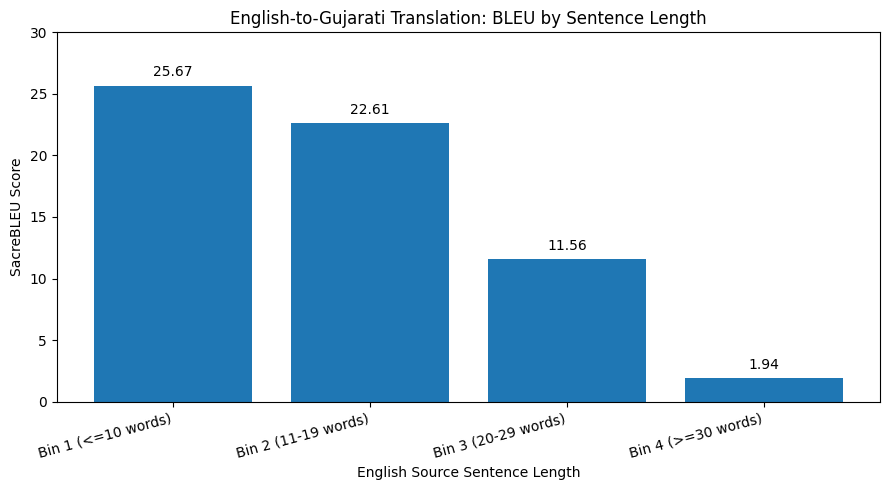

Chart saved to: /kaggle/working/opennmt_model/bleu_by_sentence_length.png


In [44]:

import matplotlib.pyplot as plt
from pathlib import Path

OUTPUT_DIR = Path("/kaggle/working/opennmt_model")

# Exclude overall BLEU so the chart compares the four length bins.
length_results = results.iloc[1:]

plt.figure(figsize=(9, 5))
bars = plt.bar(
    length_results["Test Subset"],
    length_results["SacreBLEU"]
)

plt.title("English-to-Gujarati Translation: BLEU by Sentence Length")
plt.xlabel("English Source Sentence Length")
plt.ylabel("SacreBLEU Score")
plt.ylim(0, 30)
plt.xticks(rotation=15, ha="right")

for bar, score in zip(bars, length_results["SacreBLEU"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.5,
        f"{score:.2f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()

chart_path = OUTPUT_DIR / "bleu_by_sentence_length.png"
plt.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved to:", chart_path)


In [45]:

summary = """English-to-Gujarati Neural Machine Translation Evaluation

Model: OpenNMT Transformer
Training steps: 10,000
Held-out test sentences: 19,248

Overall SacreBLEU: 18.85

Length-wise SacreBLEU:
- Bin 1 (<=10 words): 25.67 (2,675 sentences)
- Bin 2 (11-19 words): 22.61 (11,896 sentences)
- Bin 3 (20-29 words): 11.56 (4,540 sentences)
- Bin 4 (>=30 words): 1.94 (137 sentences)

Observation:
The highest BLEU score is for sentences containing 10 words or fewer.
BLEU decreases for longer sentences, suggesting that longer inputs
are more challenging for this trained translation model. The result
for sentences with 30 or more words should be interpreted cautiously
because this group contains only 137 test examples.
"""

summary_path = OUTPUT_DIR / "evaluation_summary.txt"
summary_path.write_text(summary, encoding="utf-8")

print(summary)
print("Summary saved to:", summary_path)


English-to-Gujarati Neural Machine Translation Evaluation

Model: OpenNMT Transformer
Training steps: 10,000
Held-out test sentences: 19,248

Overall SacreBLEU: 18.85

Length-wise SacreBLEU:
- Bin 1 (<=10 words): 25.67 (2,675 sentences)
- Bin 2 (11-19 words): 22.61 (11,896 sentences)
- Bin 3 (20-29 words): 11.56 (4,540 sentences)
- Bin 4 (>=30 words): 1.94 (137 sentences)

Observation:
The highest BLEU score is for sentences containing 10 words or fewer.
BLEU decreases for longer sentences, suggesting that longer inputs
are more challenging for this trained translation model. The result
for sentences with 30 or more words should be interpreted cautiously
because this group contains only 137 test examples.

Summary saved to: /kaggle/working/opennmt_model/evaluation_summary.txt


In [46]:

from pathlib import Path
import shutil
import os

WORKING_DIR = Path("/kaggle/working")
MODEL_DIR = WORKING_DIR / "opennmt_model"
DATA_DIR = WORKING_DIR / "bpcc_en_gu"

# Create a folder for final assignment results
FINAL_DIR = WORKING_DIR / "final_assignment_results"
FINAL_DIR.mkdir(parents=True, exist_ok=True)

# Copy evaluation outputs
files_to_save = [
    MODEL_DIR / "bleu_results.csv",
    MODEL_DIR / "bleu_by_sentence_length.png",
    MODEL_DIR / "evaluation_summary.txt",
    MODEL_DIR / "predictions.gu",
    MODEL_DIR / "en_gu_step_10000.pt",
    MODEL_DIR / "config.yaml",
]

for file_path in files_to_save:
    if file_path.exists():
        shutil.copy2(file_path, FINAL_DIR / file_path.name)
        print("Saved:", file_path.name)
    else:
        print("Not found, skipped:", file_path.name)

# Save the held-out test references and English inputs
for filename in ["test.en", "test.gu"]:
    source = DATA_DIR / filename
    if source.exists():
        shutil.copy2(source, FINAL_DIR / filename)
        print("Saved:", filename)

# Create a ZIP archive of the final results
zip_path = shutil.make_archive(
    str(WORKING_DIR / "final_assignment_results"),
    "zip",
    root_dir=FINAL_DIR
)

print("\nFinal folder:", FINAL_DIR)
print("ZIP archive:", zip_path)
print("\nFiles in final folder:")
for file_path in sorted(FINAL_DIR.iterdir()):
    print(f"{file_path.name}: {file_path.stat().st_size:,} bytes")


Saved: bleu_results.csv
Saved: bleu_by_sentence_length.png
Saved: evaluation_summary.txt
Saved: predictions.gu
Saved: en_gu_step_10000.pt
Saved: config.yaml
Saved: test.en
Saved: test.gu

Final folder: /kaggle/working/final_assignment_results
ZIP archive: /kaggle/working/final_assignment_results.zip

Files in final folder:
bleu_by_sentence_length.png: 139,491 bytes
bleu_results.csv: 192 bytes
config.yaml: 1,387 bytes
en_gu_step_10000.pt: 124,422,124 bytes
evaluation_summary.txt: 715 bytes
predictions.gu: 4,396,968 bytes
test.en: 1,956,648 bytes
test.gu: 4,899,826 bytes
